In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score
)

print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("TensorFlow Version:", tf.__version__)
print("Libraries imported successfully!")

I0000 00:00:1794725343.070969   98194 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794725343.071325   98194 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794725343.097639   98194 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


NumPy Version: 2.1.3
Pandas Version: 2.2.3
TensorFlow Version: 2.21.0
Libraries imported successfully!


I0000 00:00:1794725344.011689   98194 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794725344.012154   98194 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [6]:
# Load dataset

df = pd.read_csv("creditcard.csv")

# Display first five records
display(df.head())

# Dataset shape
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

# Check missing values
print("Missing Values:", df.isnull().sum().sum())

# Class distribution
print("\nClass Distribution:")
print(df['Class'].value_counts())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Dataset Shape: (284807, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-n

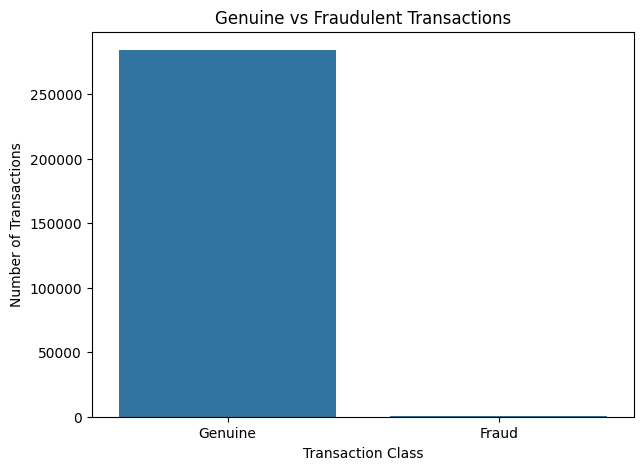

In [7]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Class')

plt.title("Genuine vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ['Genuine', 'Fraud'])

plt.show()

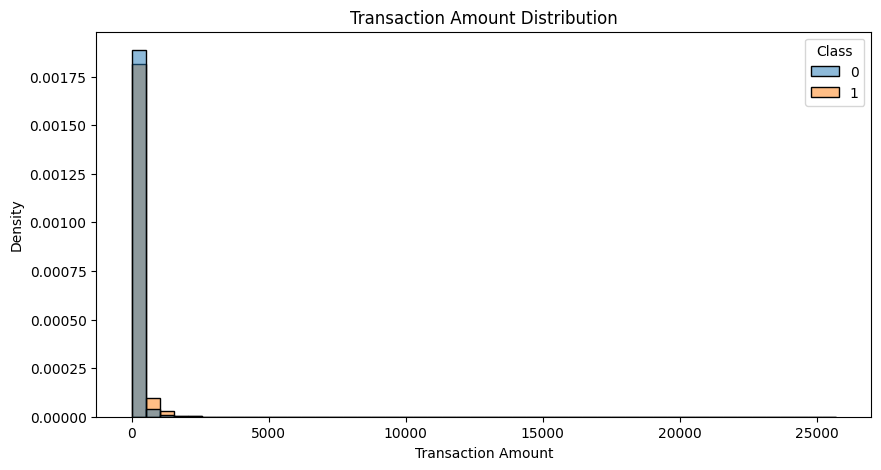

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='Amount',
    hue='Class',
    bins=50,
    stat='density',
    common_norm=False
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")

plt.show()

In [9]:
# Separate normal and fraudulent transactions

normal_data = df[df['Class'] == 0]
fraud_data = df[df['Class'] == 1]

print("Normal Transactions:", len(normal_data))
print("Fraudulent Transactions:", len(fraud_data))

print("\nNormal Data Shape:", normal_data.shape)
print("Fraud Data Shape:", fraud_data.shape)

Normal Transactions: 284315
Fraudulent Transactions: 492

Normal Data Shape: (284315, 31)
Fraud Data Shape: (492, 31)


In [10]:
# Independent features
X = df.drop('Class', axis=1)

# Target variable
y = df['Class']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (284807, 30)
Target Shape: (284807,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Data: (227845, 30)
Testing Data: (56962, 30)

Training Class Distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing Class Distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [12]:
# Select only normal transactions from training dataset

X_train_normal = X_train[y_train == 0]

print("Normal Training Transactions:", X_train_normal.shape)

# Split normal training data into training and validation

X_fit, X_val = train_test_split(
    X_train_normal,
    test_size=0.1,
    random_state=42
)

print("Autoencoder Training Data:", X_fit.shape)
print("Validation Data:", X_val.shape)

Normal Training Transactions: (227451, 30)
Autoencoder Training Data: (204705, 30)
Validation Data: (22746, 30)


In [13]:
# Initialize StandardScaler

scaler = StandardScaler()

# Fit and transform normal training data
X_fit_scaled = scaler.fit_transform(X_fit)

# Transform validation data
X_val_scaled = scaler.transform(X_val)

# Transform complete testing data
X_test_scaled = scaler.transform(X_test)

print("Training Data Shape:", X_fit_scaled.shape)
print("Validation Data Shape:", X_val_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

Training Data Shape: (204705, 30)
Validation Data Shape: (22746, 30)
Testing Data Shape: (56962, 30)


In [14]:
# Number of input features

input_dim = X_fit_scaled.shape[1]

# Input layer
input_layer = Input(shape=(input_dim,))

# Encoder layers
encoder = Dense(16, activation='relu')(input_layer)

latent = Dense(8, activation='relu')(encoder)

print("Input Features:", input_dim)
print("Latent Dimensions:", 8)

Input Features: 30
Latent Dimensions: 8


E0000 00:00:1794725408.253961   98194 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [15]:
# Decoder layers

decoder = Dense(16, activation='relu')(latent)

output_layer = Dense(input_dim, activation='linear')(decoder)

print("Decoder created successfully!")

Decoder created successfully!


In [16]:
# Create Autoencoder model

autoencoder = Model(
    inputs=input_layer,
    outputs=output_layer
)

# Display model architecture
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 30)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("Autoencoder compiled successfully!")

Autoencoder compiled successfully!


In [18]:
# Early stopping to prevent unnecessary training

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train the Autoencoder

history = autoencoder.fit(
    X_fit_scaled,
    X_fit_scaled,
    validation_data=(X_val_scaled, X_val_scaled),
    epochs=30,
    batch_size=256,
    shuffle=True,
    callbacks=[early_stop],
    verbose=1
)

print("Autoencoder Training Completed!")

Epoch 1/30
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 976us/step - loss: 0.7739 - mae: 0.5906 - val_loss: 0.6215 - val_mae: 0.5386
Epoch 2/30
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.5973 - mae: 0.5222 - val_loss: 0.5532 - val_mae: 0.5122
Epoch 3/30
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 825us/step - loss: 0.5505 - mae: 0.5047 - val_loss: 0.5197 - val_mae: 0.4985
Epoch 4/30
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 794us/step - loss: 0.5212 - mae: 0.4910 - val_loss: 0.4944 - val_mae: 0.4849
Epoch 5/30
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 794us/step - loss: 0.4999 - mae: 0.4792 - val_loss: 0.4770 - val_mae: 0.4711
Epoch 6/30
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4857 - mae: 0.4690 - val_loss: 0.4640 - val_mae: 0.4632
Epoch 7/30
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 992us/step - loss: 0.4736 - mae: 0.4618 - val_loss: 0.4543 - val_mae: 0.4577
Epoch 8/30
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 818us/step - loss: 0.4658 - mae: 0.4571 - val_loss: 0.4475 - val_mae: 0.4543
Epoch 9/30
800/800 ━━━━━━━━━━━━━━━━━━━━ 1s 7

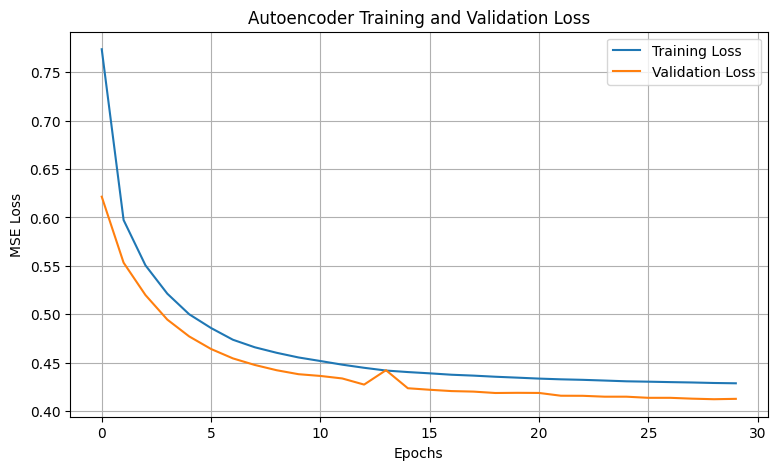

In [19]:
plt.figure(figsize=(9, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Autoencoder Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)

plt.show()

In [20]:
# Reconstruct validation data

val_reconstructed = autoencoder.predict(
    X_val_scaled,
    verbose=0
)

# Calculate reconstruction errors

val_errors = np.mean(
    np.square(X_val_scaled - val_reconstructed),
    axis=1
)

print("Validation Reconstruction Errors:")
print(val_errors[:10])

print("Mean Validation Error:", np.mean(val_errors))

Validation Reconstruction Errors:
[0.15870808 0.70649385 0.25498014 0.3133273  0.17854554 0.04676432
 0.47787946 0.73870635 0.15127539 0.4302802 ]
Mean Validation Error: 0.4120633271249806


In [21]:
# Set threshold using 99th percentile

threshold = np.percentile(val_errors, 99)

print("Anomaly Detection Threshold:", threshold)

Anomaly Detection Threshold: 2.3119858282015926


In [22]:
# Reconstruct testing data

test_reconstructed = autoencoder.predict(
    X_test_scaled,
    verbose=0
)

# Calculate reconstruction error

test_errors = np.mean(
    np.square(X_test_scaled - test_reconstructed),
    axis=1
)

# Detect anomalies

y_pred = (test_errors > threshold).astype(int)

print("Testing Completed!")

print("Total Test Transactions:", len(y_test))
print("Detected Anomalies:", np.sum(y_pred))

Testing Completed!
Total Test Transactions: 56962
Detected Anomalies: 640


In [23]:
# Create result DataFrame

results = X_test.copy()

results['Actual_Class'] = y_test
results['Reconstruction_Error'] = test_errors
results['Predicted_Class'] = y_pred

# Add prediction labels

results['Prediction'] = np.where(
    results['Predicted_Class'] == 1,
    'Fraud',
    'Normal'
)

print("Prediction Results:")
display(results.head(10))

Prediction Results:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V24,V25,V26,V27,V28,Amount,Actual_Class,Reconstruction_Error,Predicted_Class,Prediction
263020,160760.0,-0.674466,1.408105,-1.110622,-1.328366,1.388996,-1.308439,1.885879,-0.614233,0.311652,...,0.707899,-0.135837,0.045102,0.533837,0.291319,23.00,0,0.205715,0,Normal
11378,19847.0,-2.829816,-2.765149,2.537793,-1.074580,2.842559,-2.153536,-1.795519,-0.250020,3.073504,...,0.042996,-0.027660,-0.910247,0.110802,-0.511938,11.85,0,0.693476,0,Normal
147283,88326.0,-3.576495,2.318422,1.306985,3.263665,1.127818,2.865246,1.444125,-0.718922,1.874046,...,-1.483996,-0.296011,0.062823,0.552411,0.509764,76.07,0,1.120103,0,Normal
219439,141734.0,2.060386,-0.015382,-1.082544,0.386019,-0.024331,-1.074935,0.207792,-0.338140,0.455091,...,-0.067584,-0.283675,0.203529,-0.063621,-0.060077,0.99,0,0.170959,0,Normal
36939,38741.0,1.209965,1.384303,-1.343531,1.763636,0.662351,-2.113384,0.854039,-0.475963,-0.629658,...,0.619449,0.818998,-0.330525,0.046884,0.104527,1.50,0,0.278818,0,Normal
243438,151934.0,-0.345588,1.070328,-0.652790,-0.492207,0.749482,-0.949391,0.752520,0.079095,0.061269,...,0.618295,-0.438012,0.073463,-0.196700,-0.211518,8.99,0,0.182587,0,Normal
259448,159122.0,-0.864273,0.361412,-0.346667,-1.938227,-1.065839,-1.056202,-0.093590,0.095647,-2.782531,...,-0.033647,-0.488660,-0.234982,-0.578365,-0.225400,52.00,0,0.269940,0,Normal
43800,41656.0,-1.679000,0.004724,2.093100,-0.209994,1.112123,-1.254060,0.193846,-0.010860,-0.568361,...,0.409963,0.137482,0.013113,-0.143778,0.184565,3.59,0,0.249017,0,Normal
66742,52202.0,-0.806445,0.865983,1.105898,1.383957,-0.018110,0.140882,0.124651,0.603672,-0.853074,...,0.258955,-0.367384,-0.308236,0.083590,0.059612,27.92,0,0.292544,0,Normal
66499,52081.0,1.169646,-0.823924,0.467031,-0.840968,-0.850688,0.062139,-0.705097,0.094004,-1.020702,...,-0.291176,0.171156,-0.390048,0.017274,0.023729,95.25,0,0.036445,0,Normal


In [24]:
# Filter predicted fraudulent transactions

detected_fraud = results[
    results['Predicted_Class'] == 1
]

print("Total Detected Anomalies:", len(detected_fraud))

print("\nDetected Transactions:")
display(
    detected_fraud[
        [
            'Amount',
            'Actual_Class',
            'Reconstruction_Error',
            'Predicted_Class',
            'Prediction'
        ]
    ].head(20)
)

Total Detected Anomalies: 640

Detected Transactions:


,Amount,Actual_Class,Reconstruction_Error,Predicted_Class,Prediction
83371,1222.48,0,3.148836,1,Fraud
190263,0.76,0,4.735894,1,Fraud
104224,11.53,0,3.384568,1,Fraud
158999,4.16,0,2.509307,1,Fraud
205010,159.44,0,6.751714,1,Fraud
7485,1895.88,0,19.560092,1,Fraud
69372,4652.24,0,6.141772,1,Fraud
77348,0.01,1,8.493361,1,Fraud
62346,68.18,0,14.302906,1,Fraud
85891,381.81,0,2.348602,1,Fraud


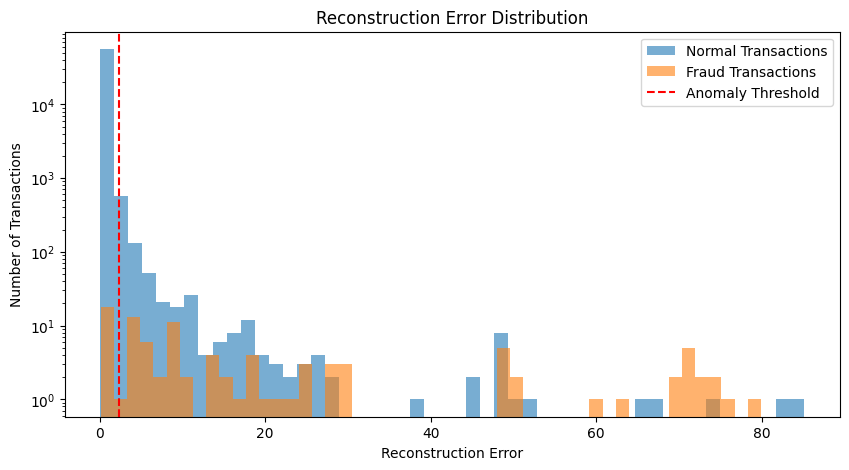

In [25]:
plt.figure(figsize=(10, 5))

plt.hist(
    test_errors[y_test.to_numpy() == 0],
    bins=50,
    alpha=0.6,
    label='Normal Transactions'
)

plt.hist(
    test_errors[y_test.to_numpy() == 1],
    bins=50,
    alpha=0.6,
    label='Fraud Transactions'
)

plt.axvline(
    threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.title("Reconstruction Error Distribution")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Transactions")
plt.yscale('log')
plt.legend()

plt.show()

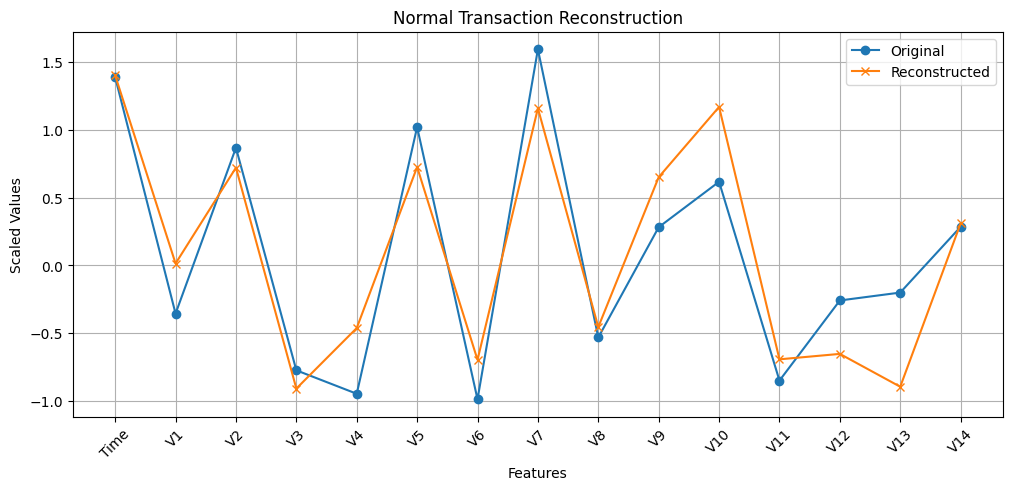

In [26]:
# Find one normal and one fraudulent test transaction

normal_index = np.where(y_test.to_numpy() == 0)[0][0]
fraud_index = np.where(y_test.to_numpy() == 1)[0][0]

# Feature names
feature_names = X.columns[:15]

# Plot normal transaction
plt.figure(figsize=(12, 5))

plt.plot(
    feature_names,
    X_test_scaled[normal_index][:15],
    marker='o',
    label='Original'
)

plt.plot(
    feature_names,
    test_reconstructed[normal_index][:15],
    marker='x',
    label='Reconstructed'
)

plt.title("Normal Transaction Reconstruction")
plt.xlabel("Features")
plt.ylabel("Scaled Values")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.show()

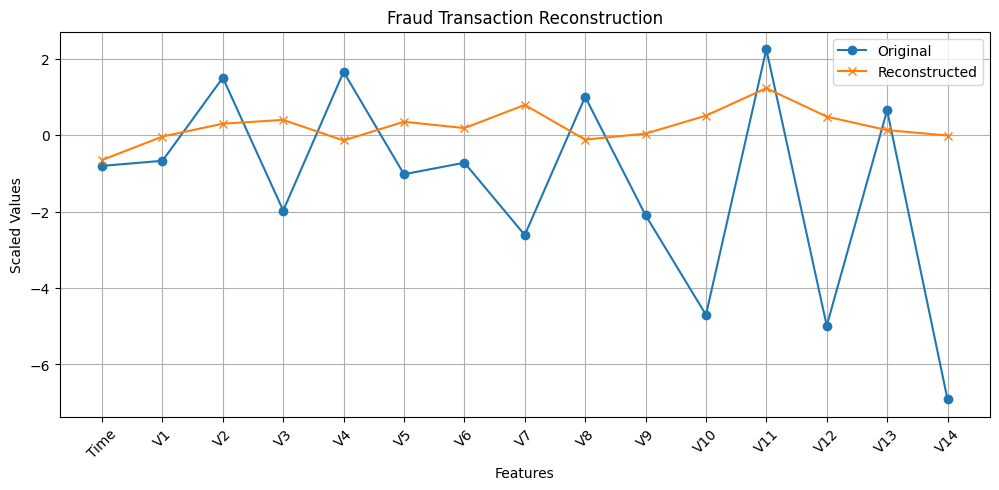

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    feature_names,
    X_test_scaled[fraud_index][:15],
    marker='o',
    label='Original'
)

plt.plot(
    feature_names,
    test_reconstructed[fraud_index][:15],
    marker='x',
    label='Reconstructed'
)

plt.title("Fraud Transaction Reconstruction")
plt.xlabel("Features")
plt.ylabel("Scaled Values")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)

plt.show()

In [28]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(y_test, test_errors)

pr_auc = average_precision_score(y_test, test_errors)

print("MODEL EVALUATION RESULTS")
print("-------------------------")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("ROC-AUC Score:", roc_auc)
print("Average Precision:", pr_auc)

MODEL EVALUATION RESULTS
-------------------------
Accuracy: 0.9898528843790597
Precision: 0.125
Recall: 0.8163265306122449
F1 Score: 0.21680216802168023
ROC-AUC Score: 0.9436693923489486
Average Precision: 0.37694053245566544


In [29]:
print("Classification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['Normal', 'Fraud'],
        zero_division=0
    )
)

Classification Report:

              precision    recall  f1-score   support

      Normal       1.00      0.99      0.99     56864
       Fraud       0.12      0.82      0.22        98

    accuracy                           0.99     56962
   macro avg       0.56      0.90      0.61     56962
weighted avg       1.00      0.99      0.99     56962



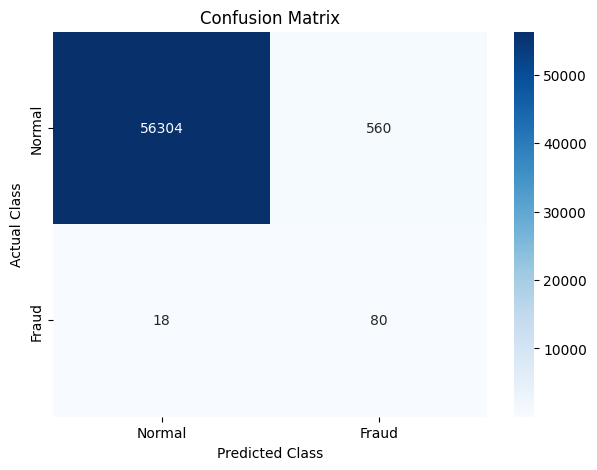

In [30]:
# Calculate confusion matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Fraud'],
    yticklabels=['Normal', 'Fraud']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [31]:
import joblib

# Save Autoencoder model
autoencoder.save("credit_card_autoencoder.keras")

# Save scaler
joblib.dump(scaler, "credit_card_scaler.pkl")

# Save threshold
np.save("fraud_threshold.npy", threshold)

print("Model saved successfully!")
print("Scaler saved successfully!")
print("Threshold saved successfully!")

Model saved successfully!
Scaler saved successfully!
Threshold saved successfully!
